### **Soil Moisture Prediction [1D CNN LSTM]**

**<u>Dataset I</u>**

Description: Predict soil moisture from sensor telemetry

Source: https://zenodo.org/records/10991581

In [1]:
import random
import pandas as pd
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow import keras
from sklearn.preprocessing import MinMaxScaler
from keras.models import Sequential, Model
from keras.layers import LSTM, Dense, Dropout, Conv1D, MaxPooling1D, Input,LayerNormalization, MultiHeadAttention, Add
from kerastuner.tuners import RandomSearch
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from tensorflow.keras.optimizers import AdamW
import keras_tuner as kt
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
import time
import math

sns.set_style('darkgrid')

random.seed(42); np.random.seed(42); tf.random.set_seed(42)

C:\Users\ptong\AppData\Local\Temp\ipykernel_28576\2259566691.py:11: DeprecationWarning: `import kerastuner` is deprecated, please use `import keras_tuner`.
  from kerastuner.tuners import RandomSearch


In [2]:
"""---------------------------------
Load dataset
------------------------------------"""

DATA = pd.read_csv('Edge_IoT_Predictive_Irrigation_Dataset.csv')
DATA["Timestamp"] = pd.to_datetime(DATA["Timestamp"])
DATA = DATA.sort_values(by='Timestamp')
DATA.head()
# DATA.dtypes

C:\Users\ptong\AppData\Local\Temp\ipykernel_28576\2394318767.py:6: UserWarning: Parsing dates in %d/%m/%Y %H:%M format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  DATA["Timestamp"] = pd.to_datetime(DATA["Timestamp"])


,Timestamp,Day,Time,Temperature_C,Humidity_pct,Soil_Moisture_pct,Light_Intensity,Pump_Status
537,2026-04-01 00:00:00,1,0:00,25.1,83,64.1,0,0
455,2026-04-01 00:30:00,1,0:30,25.0,84,63.4,0,0
456,2026-04-01 01:00:00,1,1:00,25.0,86,63.4,0,0
405,2026-04-01 01:30:00,1,1:30,25.0,87,62.8,0,0
436,2026-04-01 02:00:00,1,2:00,25.0,85,63.1,0,0


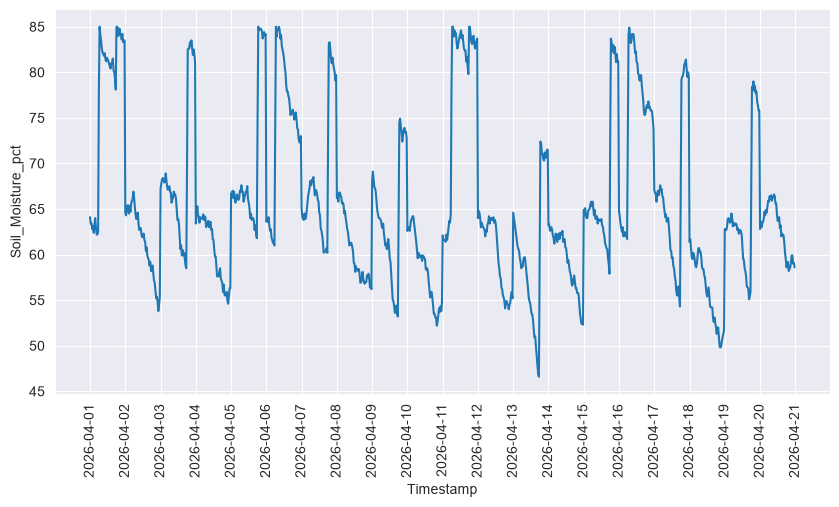

In [3]:
"""---------------------------------
Visualize the raw dataset
------------------------------------"""
import matplotlib.dates as mdates

fig, ax = plt.subplots(figsize = (10,5))
sns.lineplot(x='Timestamp', y='Soil_Moisture_pct', data=DATA)
ax.xaxis.set_major_locator(mdates.DayLocator(interval=1))
ax.tick_params(axis='x', rotation=90)
ax.grid(True)
plt.show()

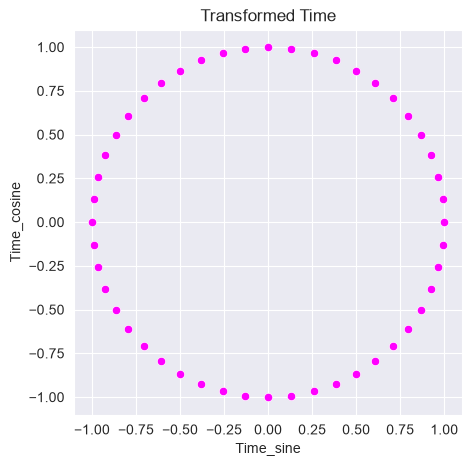

In [4]:
"""---------------------------------
Transform Time Column to Sine & Cosine
------------------------------------"""

DATA['Time'].dtypes # str
DATA['Time'] = pd.to_datetime(DATA['Time'], format='%H:%M')

DATA['Hour'] = DATA['Time'].dt.hour	+ DATA['Time'].dt.minute/60.0
# DATA['Hour'].head()

DATA['Time_sine'] = np.sin(2 * np.pi * DATA["Hour"]/24.0)
DATA['Time_cosine'] = np.cos(2 * np.pi * DATA["Hour"]/24.0)

fig, ax = plt.subplots(figsize=(5,5))
sns.scatterplot(x='Time_sine', y='Time_cosine', data=DATA, color='magenta')

ax.grid(True)
plt.title('Transformed Time')
plt.show()



In [5]:
"""---------------------------------
Multivariate Architecture Initialization
------------------------------------"""
FEATURES_INPUT = ['Soil_Moisture_pct','Time_sine','Time_cosine', 'Temperature_C', 'Humidity_pct', 'Light_Intensity']
LOOKBACK = 24

''' Create Sliding Windows with lookback period for LSTM'''
def create_dataset(DATA, lookback=1):
    x, y = [], []

    for i in range(lookback, len(DATA)):
        x.append(DATA[(i- lookback):i, :])
        
        y.append(DATA[i, 0]) 

    return np.array(x), np.array(y)


In [6]:
"""---------------------------------
Split into Train-test
------------------------------------"""

# Specifying the start-end rows for train-test-val splits
SAMPLES = len(DATA)
TRAIN_END = int(SAMPLES*0.7)
VAL_END = int(SAMPLES*0.85)

TRAIN_DATA = DATA[:TRAIN_END]
VAL_DATA = DATA[TRAIN_END:VAL_END]
TEST_DATA = DATA[VAL_END:SAMPLES]

SCALER = MinMaxScaler(feature_range=(0, 1))

train_scaled = SCALER.fit_transform(TRAIN_DATA[FEATURES_INPUT].values)
val_scaled = SCALER.transform(VAL_DATA[FEATURES_INPUT].values)
test_scaled = SCALER.transform(TEST_DATA[FEATURES_INPUT].values)

X_train, y_train = create_dataset(train_scaled, lookback=LOOKBACK)
X_val, y_val = create_dataset(val_scaled, lookback=LOOKBACK)
X_test, y_test = create_dataset(test_scaled, lookback=LOOKBACK)

# Scaling for soil_moisture (training set)
SM_SCALER = MinMaxScaler(feature_range=(0, 1))
SM_SCALER.fit(TRAIN_DATA[['Soil_Moisture_pct']])

X_train.shape
TRAIN_DATA[FEATURES_INPUT].columns


Index(['Soil_Moisture_pct', 'Time_sine', 'Time_cosine', 'Temperature_C',
       'Humidity_pct', 'Light_Intensity'],
      dtype='str')

In [ ]:
"""---------------------------------
Model Architecture
------------------------------------"""
# Record training time start...
trainingtime_start = time.perf_counter()

def build_model(hp):

    regressor = Sequential([

        Conv1D(
            filters=hp.Int('conv1D', min_value=32, max_value=128, step=32),
            kernel_size=hp.Int('conv_kernel', min_value=3, max_value=9, step=2),
            activation='relu',
            input_shape=(X_train.shape[1], X_train.shape[2]),
            padding='same',
            kernel_regularizer=tf.keras.regularizers.l2(hp.Choice('l2_reg', [1e-4, 1e-5, 0.0])),
            dilation_rate=hp.Choice('dilation', [1, 2])
        ),
        # MaxPooling1D(pool_size=2),

        LSTM(units=hp.Int('input_unit1', min_value=32, max_value=128, step=32), 
             return_sequences = True
             
        ),
        LayerNormalization(),

        Dropout(rate=hp.Float('drop_out1', min_value=0.1, max_value=0.3, step=0.1)),
        
        LSTM(units=hp.Int('input_unit2', min_value=16, max_value=64, step=16), 
                return_sequences = False, 

        ),
        Dropout(rate=hp.Float('drop_out2', min_value=0.1, max_value=0.3, step=0.1)),

        Dense(1)
    
    ])

    regressor.compile(
        optimizer=AdamW(
            learning_rate=hp.Choice('LR', values=[1e-2, 1e-3,1e-4]),
            weight_decay=hp.Choice('WD', values=[1e-3, 1e-4, 1e-5]),
        )
        
        , loss='huber'
    )
    return regressor

callbacks = [
    EarlyStopping(
        monitor='val_loss',
        patience=15,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=5,
        min_lr=1e-6,
        verbose=1
    )
]

# Create tuner object
tuner = RandomSearch(
    build_model,
    objective = 'val_loss',
    max_trials = 10,
    executions_per_trial = 1,
    directory='soil_moisture_multivar',
    project_name='lstm_tuning_1D-CNN LSTM',
    overwrite=True
)

# Run the search
tuner.search(
    x=X_train, y=y_train,
    epochs=50,
    batch_size=20,
    validation_data = (X_val, y_val),
    callbacks = callbacks
)

final_model = tuner.get_best_models(num_models=1)[0]

# Compute training time duration...
trainingtime_end = time.perf_counter()
training_duration = trainingtime_end - trainingtime_start

print(f"Training Time: {training_duration:.4f} seconds")
# final_model.summary()

Trial 10 Complete [00h 00m 17s]
val_loss: 0.003538801334798336

Best val_loss So Far: 0.0026111514307558537
Total elapsed time: 00h 03m 18s
Training Time: 198.5931 seconds


c:\Users\ptong\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\saving\saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam_w', because it has 2 variables whereas the saved optimizer has 26 variables. 
  saveable.load_own_variables(store)


In [8]:
"""---------------------------------
Prediction
------------------------------------"""
y_pred = final_model.predict(X_test)
print(max(y_pred))

# Rescale back
y_pred = y_pred[:, 0].reshape(-1, 1)
y_pred_actual = SM_SCALER.inverse_transform(y_pred)
y_pred_actual = y_pred_actual.flatten()

# y_test.shape
y_test = y_test.reshape(-1, 1)
y_test_actual = SM_SCALER.inverse_transform(y_test)
y_test_actual = y_test_actual.flatten()

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
[0.8914309]


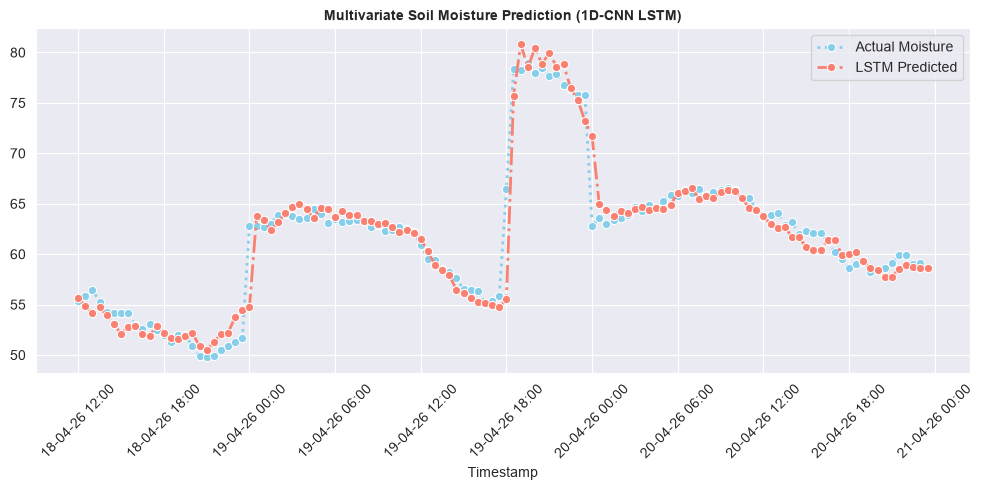

In [9]:
"""---------------------------------
Visualize output results
------------------------------------"""
DATETIME_TEST = DATA['Timestamp'].iloc[VAL_END+LOOKBACK:SAMPLES]


fig, ax = plt.subplots(figsize = (10,5))
sns.lineplot(x=DATETIME_TEST, y=y_test_actual.flatten(), label='Actual Moisture', linestyle=':', color='skyblue', linewidth=2, marker="o")
sns.lineplot(x=DATETIME_TEST, y=y_pred_actual.flatten(), label='LSTM Predicted', linestyle='-.', color='salmon', linewidth=2, marker="o")
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%d-%m-%y %H:%M'))

plt.title('Multivariate Soil Moisture Prediction (1D-CNN LSTM)', fontsize=10, fontweight='bold')
ax.tick_params(axis='x', rotation=45)
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()

In [10]:
"""---------------------------------
Summary Results
------------------------------------"""

print(f"""
Metric       | Value
------------------------
MAE          | {round(mean_absolute_error(y_pred_actual, y_test_actual),2)}
MSE          | {round(mean_squared_error(y_pred_actual, y_test_actual),2)}
RMSE         | {round(math.sqrt(mean_squared_error(y_pred_actual, y_test_actual)),2)}
R2 score     | {round((r2_score(y_pred_actual, y_test_actual)),2)}
""")



Metric       | Value
------------------------
MAE          | 1.01
MSE          | 3.27
RMSE         | 1.81
R2 score     | 0.93

